## 1. Предложите новый метод инициализации центроидов кластеров для алгоритма K-средних

Методы инициализации используются для выбора начальных центроидов в алгоритме K-средних (K-Means). От того, как выбраны начальные центры, зависит качество кластеризации и скорость сходимости алгоритма.

### 1. Метод подделки (Forgy)

В этом методе случайным образом выбираются K точек из исходных данных, и они используются как начальные центроиды.

Преимущество метода заключается в его простоте и высокой скорости, так как он требует минимальных вычислений. Кроме того, центры всегда находятся внутри распределения данных, потому что выбираются из существующих точек.

Недостаток метода заключается в том, что он может выбрать несколько центров, расположенных очень близко друг к другу. В результате некоторые области данных могут остаться без центров. Также результаты могут сильно зависеть от случайности, поэтому алгоритм может давать разные результаты при разных запусках.

### 2. Случайное разбиение (Random Partition)

В этом методе все точки случайным образом распределяются по K кластерам. После этого для каждого кластера вычисляется центр как среднее значение координат точек.

Преимущество метода заключается в простоте реализации и в том, что центры отражают общее распределение данных.

Недостаток состоит в том, что случайное распределение точек может привести к появлению неравномерных кластеров. Некоторые кластеры могут быть слишком маленькими, а другие слишком большими, что ухудшает начальное расположение центров и может замедлить сходимость алгоритма.

### 3. K-Means++

В этом методе первый центр выбирается случайно, а каждый следующий выбирается с вероятностью, пропорциональной квадрату расстояния до ближайшего уже выбранного центра.

Преимущество метода заключается в более качественной начальной инициализации центров. Обычно это приводит к лучшим результатам кластеризации и более быстрой сходимости алгоритма.

Недостатком является более сложная реализация и немного большие вычислительные затраты на этапе инициализации. Кроме того, этот метод не всегда учитывает плотность данных и может выбрать центр в разреженной области.

### 4. Плотностно-отдалённый выбор

Можно предложить метод, при котором первый центр выбирается из области с наибольшей плотностью точек. После этого последующие центры выбираются так, чтобы они были максимально удалены от уже выбранных центров, но при этом находились в областях с высокой плотностью данных.

Преимущество такого метода заключается в том, что он учитывает структуру данных и позволяет равномерно покрыть пространство признаков. Кроме того, он менее чувствителен к выбросам.

Недостатком является более высокая вычислительная сложность, поскольку необходимо оценивать плотность точек, а также необходимость настройки дополнительных параметров.

## 2. Как можно использовать кластеризацию для ускорения модели KNN

Алгоритм KNN (K-ближайших соседей) работает следующим образом: для нового объекта вычисляется расстояние до всех точек обучающей выборки, после чего выбираются K ближайших соседей.

Главная проблема этого алгоритма заключается в том, что при большом количестве данных вычисление расстояний до всех точек становится очень медленным.

Ускорить алгоритм можно с помощью кластеризации.

### 1. Кластеризация данных

Сначала обучающая выборка разбивается на кластеры, например с помощью алгоритма K-Means.

Затем для каждого кластера вычисляется его центр.

Когда появляется новый объект:

1. Сначала определяется, к какому кластеру он ближе всего.
2. Затем поиск ближайших соседей выполняется только внутри этого кластера или нескольких ближайших кластеров.

Это позволяет значительно уменьшить количество точек, для которых необходимо вычислять расстояние.

### 2. Использование kd-tree

Другой способ ускорения заключается в использовании структуры данных kd-tree.

KD-tree — это структура данных, которая рекурсивно делит пространство признаков на области. Каждое разбиение происходит по одной из координат.

Благодаря такой структуре можно быстро исключать области пространства, в которых не могут находиться ближайшие соседи. Это позволяет выполнять поиск соседей значительно быстрее, чем при полном переборе всех точек.

## 2. Введение: предварительная обработка данных

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.mixture import GaussianMixture
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from collections import Counter
from collections import deque
from sklearn.neighbors import BallTree

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [3]:
def replace_features(x):
    return x.replace('"', '').replace('[', '').replace(']', '').replace("'", '').replace(' ', '')

train['replace_features'] = train['features'].apply(replace_features)
test['replace_features'] = test['features'].apply(replace_features)

In [4]:
features_list = []
for feature in train['replace_features']:
    for f in feature.split(','):
        features_list.append(f)
        
cnt = Counter(features_list)
cnt.most_common(21)

[('Elevator', 19059),
 ('HardwoodFloors', 17317),
 ('CatsAllowed', 17229),
 ('DogsAllowed', 16134),
 ('Doorman', 15353),
 ('Dishwasher', 15024),
 ('NoFee', 13369),
 ('LaundryinBuilding', 12090),
 ('FitnessCenter', 9717),
 ('Pre-War', 6762),
 ('LaundryinUnit', 6294),
 ('RoofDeck', 4774),
 ('OutdoorSpace', 3816),
 ('DiningRoom', 3677),
 ('HighSpeedInternet', 3150),
 ('', 2313),
 ('Balcony', 2181),
 ('SwimmingPool', 2012),
 ('LaundryInBuilding', 1941),
 ('NewConstruction', 1859),
 ('Terrace', 1602)]

In [5]:
most_common_features = [i[0] for i in cnt.most_common(21) if i[0] != '']
print(most_common_features)

['Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace']


In [6]:
for feature in most_common_features:
    train[feature] = train['replace_features'].str.contains(feature).astype('int')
    test[feature] = test['replace_features'].str.contains(feature).astype('int')
 
features = ['bathrooms',  'bedrooms', 'interest_level'] + most_common_features
target = 'price'

train_X = train[features]
train_y = train[target]

test_X = test[features]
test_y = test[target]

## 3. KMeans

Для оценки качества кластеризации можно использовать несколько метрик.

Первая метрика — **inertia**. Она показывает сумму квадратов расстояний от каждой точки до центра своего кластера. Эта величина отражает компактность кластеров. Чем меньше значение inertia, тем ближе точки расположены к центрам кластеров и тем более компактными считаются кластеры. Поэтому для этой метрики меньшие значения считаются лучшими.

Вторая метрика — **silhouette score**. Она показывает, насколько хорошо точки внутри одного кластера похожи друг на друга и насколько сильно они отличаются от точек из других кластеров. Значение этой метрики лежит в диапазоне от -1 до 1. Чем ближе значение к 1, тем лучше разделены кластеры и тем качественнее выполнена кластеризация.

In [7]:
class MyKMeans:
    def __init__(self, n_clusters=10, n_init=10, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None

    def _distance_matrix(self, X, centers):
        diff = X[:, None, :] - centers[None, :, :]
        return np.sqrt(np.sum(diff ** 2, axis=2))

    def _update_centers(self, X, labels, centers):
        new_centers = centers.copy()
        for i in range(self.n_clusters):
            points = X[labels == i]
            if points.size > 0:
                new_centers[i] = points.mean(axis=0)
        return new_centers

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)

        n_samples = X.shape[0]
        best_inertia = float("inf")
        best_labels = None
        best_centers = None

        for _ in range(self.n_init):
            centers = X[rng.choice(n_samples, self.n_clusters, replace=False)]

            for _ in range(self.max_iter):
                distances = self._distance_matrix(X, centers)
                labels = np.argmin(distances, axis=1)

                new_centers = self._update_centers(X, labels, centers)

                if np.linalg.norm(new_centers - centers) <= self.tol:
                    centers = new_centers
                    break

                centers = new_centers

            inertia = np.sum((X - centers[labels]) ** 2)

            if inertia < best_inertia:
                best_inertia = inertia
                best_labels = labels.copy()
                best_centers = centers.copy()

        self.cluster_centers_ = best_centers
        self.labels_ = best_labels
        self.inertia_ = best_inertia

        return self

    def predict(self, X):
        distances = self._distance_matrix(X, self.cluster_centers_)
        return np.argmin(distances, axis=1)

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

In [8]:
model = MyKMeans(n_clusters=30, n_init=10, random_state=0)

labels = model.fit_predict(train[['latitude', 'longitude']].values)
inertia = model.inertia_

print("Искажение:", inertia)

sil_score = silhouette_score(train[['latitude', 'longitude']], labels)
print("Оценка силуэта:", sil_score)

Искажение: 16.161308941823787
Оценка силуэта: 0.41266980986564855


In [9]:
k_means = KMeans(n_clusters=30, n_init=10, random_state=0)
k_means.fit(train[['latitude', 'longitude']])

train_pred = k_means.predict(train[['latitude', 'longitude']])
test_pred = k_means.predict(test[['latitude', 'longitude']])

print("Искажениe:", k_means.inertia_)

sil_score = silhouette_score(train[['latitude', 'longitude']], k_means.labels_)
print("Оценка силуэта:", sil_score)

Искажениe: 4.428455045004578
Оценка силуэта: 0.468597667458372


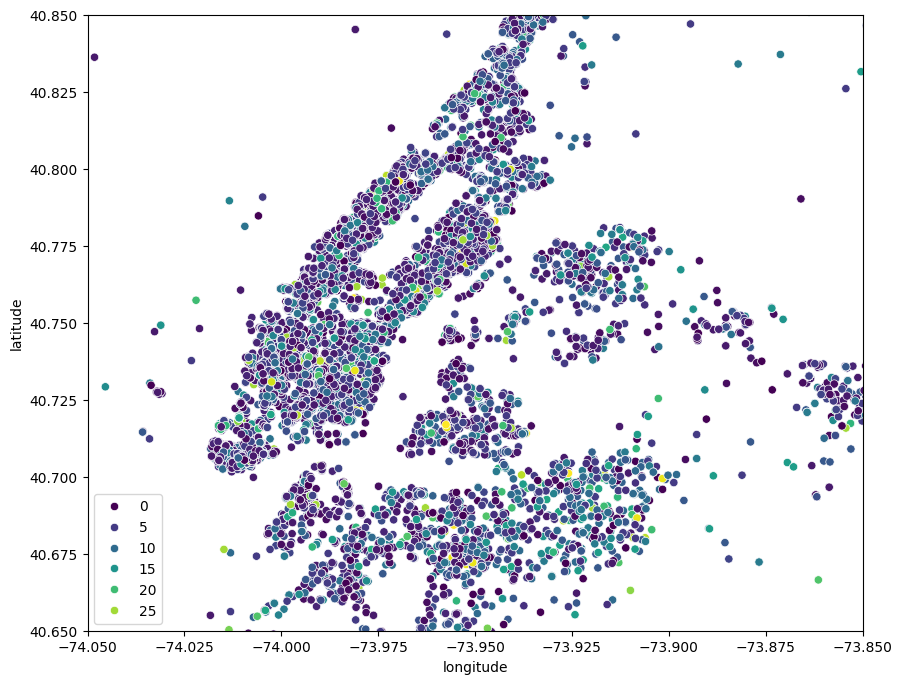

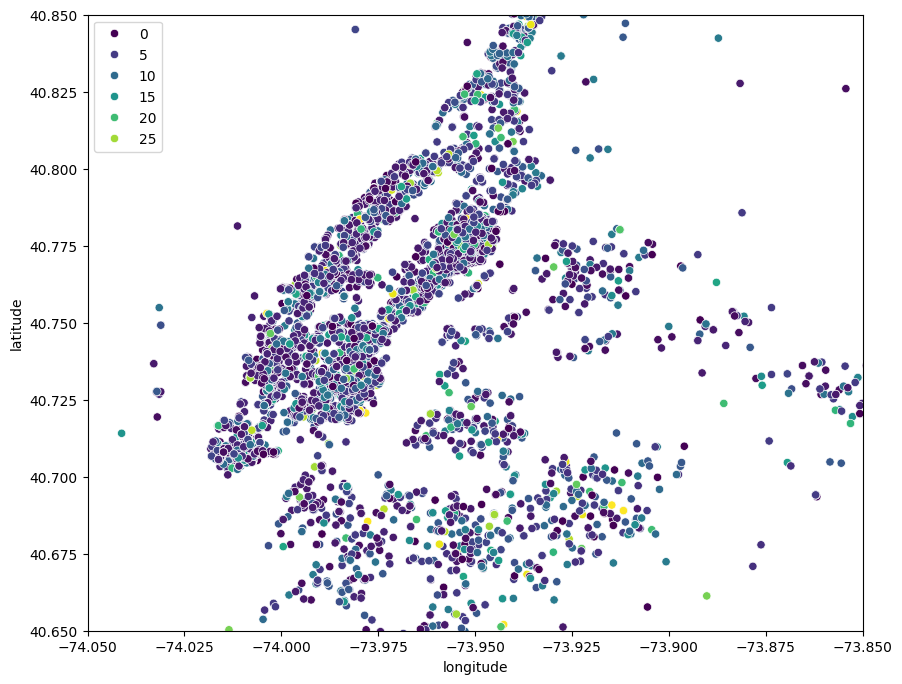

In [38]:
def show_scatterplot(x, y, hue):
    plt.figure(figsize=(10, 8))
    scatter = sns.scatterplot(x=x, y=y, hue=hue, palette='viridis')
    scatter.set(xlim=(-74.05,-73.85))
    scatter.set(ylim=(40.65,40.85))
    plt.show()
    
show_scatterplot(x=train['longitude'], y=train['latitude'], hue=train_pred)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred)

In [11]:
mms = MinMaxScaler()
lasso = Lasso(random_state=42)

df_metrics = pd.DataFrame()
def print_metrics(train, test, model):
    global df_metrics
    train_x_mms = mms.fit_transform(train)
    test_x_mms = mms.transform(test)

    lasso.fit(train_x_mms, train_y)

    train_predict = lasso.predict(train_x_mms)
    test_predict = lasso.predict(test_x_mms)

    metrics_dict = {
        'Model': model,
        'Train MAE': mean_absolute_error(train_y, train_predict),
        'Test MAE': mean_absolute_error(test_y, test_predict),
        'Train RMSE': mean_squared_error(train_y, train_predict)**0.5,
        'Test RMSE': mean_squared_error(test_y, test_predict)**0.5,
        'Train R2': r2_score(train_y, train_predict),
        'Test R2': r2_score(test_y, test_predict)
    }

    for k, v in metrics_dict.items():
        print(f"{k}: {v}")

    df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

    return lasso.coef_

In [12]:
coef_base = print_metrics(train_X, test_X, 'Base Lasso')

Model: Base Lasso
Train MAE: 690.6967986092563
Test MAE: 679.4449600453096
Train RMSE: 1005.1510196355723
Test RMSE: 972.0741648306383
Train R2: 0.6056108592809226
Test R2: 0.6015130187847189


In [13]:
train_cluster_X = train_X.copy()
train_cluster_X['cluster'] = train_pred
test_cluster_X = test_X.copy()
test_cluster_X['cluster'] = test_pred

coef_new = print_metrics(train_cluster_X, test_cluster_X, 'KMeans Lasso')

Model: KMeans Lasso
Train MAE: 686.3177767335206
Test MAE: 673.5317146243618
Train RMSE: 1000.1035762737013
Test RMSE: 966.2285535504744
Train R2: 0.6095618252414212
Test R2: 0.6062912468276374


In [14]:
features_cluster = features + ['cluster']
feature_importance = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_new)
})
feature_importance = feature_importance.sort_values('coef', ascending=True)
feature_importance

,feature,coef
5,CatsAllowed,0.000000
18,Balcony,0.000000
19,SwimmingPool,31.531047
21,NewConstruction,35.691391
15,OutdoorSpace,41.925209
12,Pre-War,52.415115
6,DogsAllowed,66.401012
9,NoFee,78.722619
14,RoofDeck,106.569420
4,HardwoodFloors,109.925304


## 4. DBSCAN

In [15]:
import numpy as np
from collections import deque
from sklearn.neighbors import BallTree

class MyDBSCAN:

    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = None
        self.n_clusters_ = 0

    def _region_query(self, tree, point):
        return tree.query_radius(point.reshape(1, -1), r=self.eps)[0]

    def _expand(self, X, tree, labels, visited, start_idx, neighbors, cluster_id):
        queue = deque(neighbors)

        while queue:
            idx = queue.popleft()

            if not visited[idx]:
                visited[idx] = True
                near = self._region_query(tree, X[idx])

                if near.size >= self.min_samples:
                    queue.extend(near)

            if labels[idx] == -1:
                labels[idx] = cluster_id

    def fit(self, X):
        n_samples = X.shape[0]

        labels = np.full(n_samples, -1)
        visited = np.zeros(n_samples, dtype=bool)

        tree = BallTree(X)

        cluster_id = 0

        for idx in range(n_samples):

            if visited[idx]:
                continue

            visited[idx] = True

            neighbors = self._region_query(tree, X[idx])

            if neighbors.size < self.min_samples:
                labels[idx] = -1
                continue

            labels[idx] = cluster_id

            self._expand(X, tree, labels, visited, idx, neighbors, cluster_id)

            cluster_id += 1

        self.labels_ = labels
        self.n_clusters_ = cluster_id

        return self

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

In [16]:
train['train'] = 1
test['train'] = 0
full_df = pd.concat([train, test]).reset_index(drop=True)


model = MyDBSCAN(eps=0.001, min_samples=5)
labels = model.fit_predict(full_df[['latitude', 'longitude']].values)

sil_score = silhouette_score(full_df[['latitude', 'longitude']], labels)
print("Оценка силуэта (MyDBSCAN):", sil_score)


dbscan = DBSCAN(eps=0.001, min_samples=5)
pred = dbscan.fit_predict(full_df[['latitude', 'longitude']])

sil_score = silhouette_score(full_df[['latitude', 'longitude']], dbscan.labels_)
print("Оценка силуэта (sklearn):", sil_score)

Оценка силуэта (MyDBSCAN): -0.17213582938440083
Оценка силуэта (sklearn): -0.17213582938440083


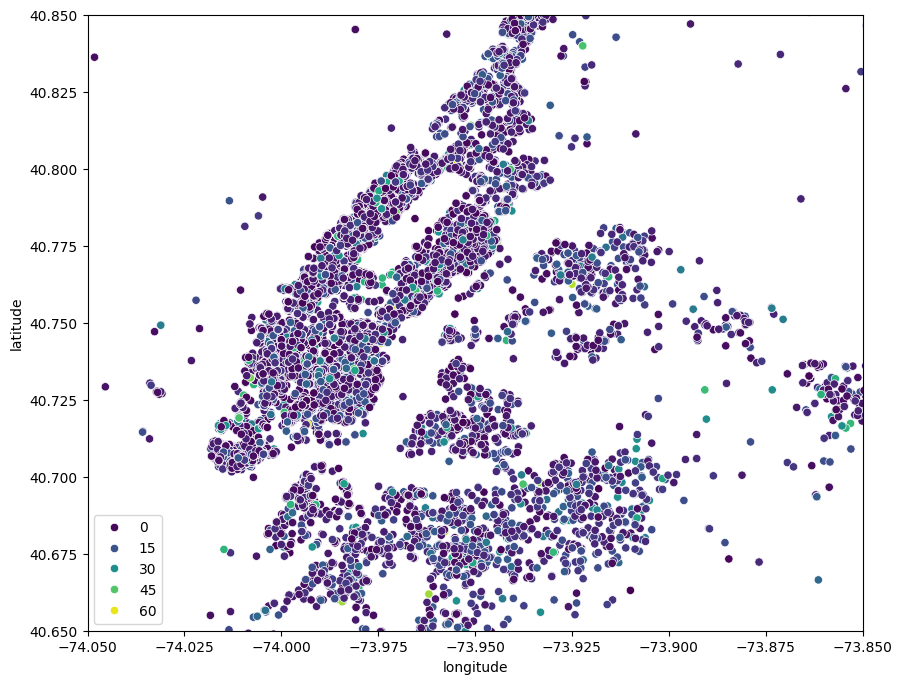

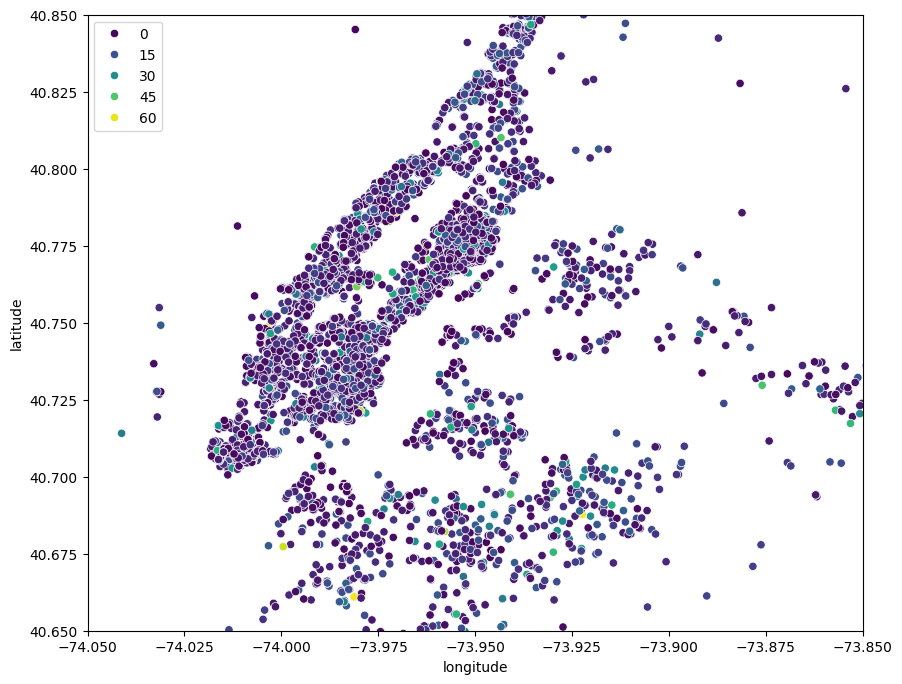

In [39]:
train_pred_dbscan = pred[:train.shape[0]]
test_pred_dbscan = pred[train.shape[0]:]

show_scatterplot(x=train['longitude'], y=train['latitude'], hue=train_pred_dbscan)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred_dbscan)

In [18]:
train_dbscan_X = train_X.copy()
train_dbscan_X['cluster'] = train_pred_dbscan
test_dbscan_X = test_X.copy()
test_dbscan_X['cluster'] = test_pred_dbscan

coef_dbscan = print_metrics(train_dbscan_X, test_dbscan_X, 'DBSCAN Lasso')

Model: DBSCAN Lasso
Train MAE: 680.7358264358159
Test MAE: 668.2765562406203
Train RMSE: 993.8243951380069
Test RMSE: 962.0399456220832
Train R2: 0.614449190422317
Test R2: 0.6096973088547092


In [19]:
features_cluster = features + ['cluster']
feature_importance_dbscan = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_dbscan)
})
feature_importance_dbscan = feature_importance_dbscan.sort_values('coef', ascending=True)
feature_importance_dbscan

,feature,coef
5,CatsAllowed,0.000000
18,Balcony,0.000000
21,NewConstruction,2.513493
19,SwimmingPool,32.178338
15,OutdoorSpace,43.032411
12,Pre-War,57.459528
6,DogsAllowed,76.446586
9,NoFee,86.302644
14,RoofDeck,105.510730
8,Dishwasher,120.562048


## 5. AgglomerativeClustering

Agglomerative silhouette: 0.4223539104459664


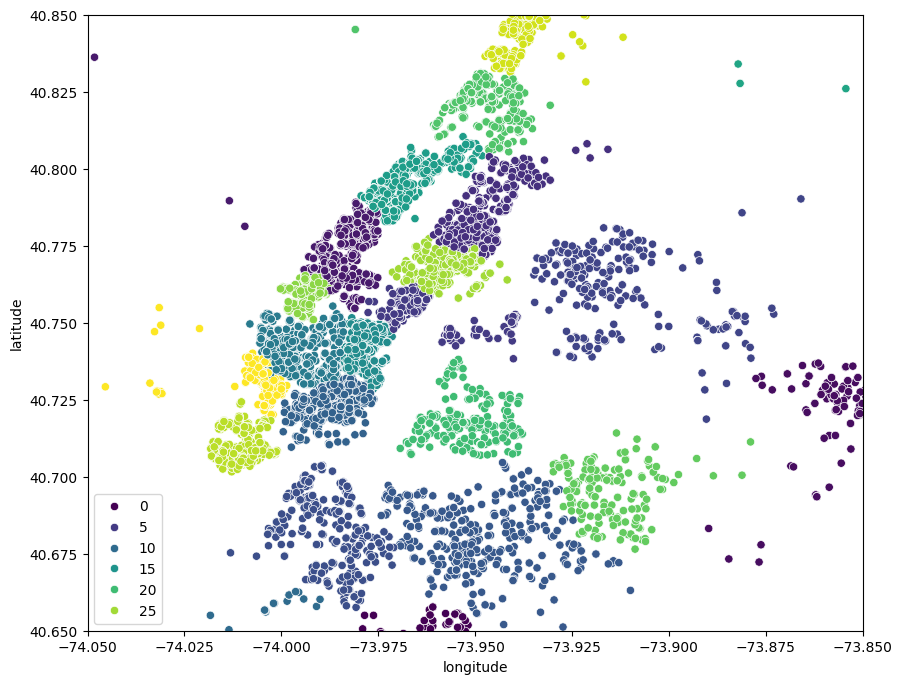

In [40]:
data_X = pd.concat([train_X, test_X]).reset_index(drop=True)
data_y = pd.concat([train_y, test_y]).reset_index(drop=True)
sample_idx = data_X.sample(20000, random_state=42).index
sample_data = data_X.loc[sample_idx]
sample_target = data_y.loc[sample_idx]

sample_cluster = full_df.loc[sample_idx]
sample = sample_cluster[['latitude', 'longitude']]
ac = AgglomerativeClustering(n_clusters=30)
ac.fit(sample)
labels = ac.labels_

sil_score = silhouette_score(sample, labels)
print("Agglomerative silhouette:", sil_score)
show_scatterplot(x=sample['longitude'], y=sample['latitude'], hue=labels)

In [21]:
sample_data['cluster'] = labels
ac_train_X, ac_test_X, ac_train_y, ac_test_y = train_test_split(
    sample_data, sample_target, test_size=0.2, random_state=42
)

train_x_mms = mms.fit_transform(ac_train_X)
test_x_mms = mms.transform(ac_test_X)

lasso.fit(train_x_mms, ac_train_y)
ac_coef = lasso.coef_

train_predict = lasso.predict(train_x_mms)
test_predict = lasso.predict(test_x_mms)

metrics_dict = {
    'Model': 'AgglomerativeClustering Lasso',
    'Train MAE': mean_absolute_error(ac_train_y, train_predict),
    'Test MAE': mean_absolute_error(ac_test_y, test_predict),
    'Train RMSE': mean_squared_error(ac_train_y, train_predict)**0.5,
    'Test RMSE': mean_squared_error(ac_test_y, test_predict)**0.5,
    'Train R2': r2_score(ac_train_y, train_predict),
    'Test R2': r2_score(ac_test_y, test_predict)
}

for k, v in metrics_dict.items():
    print(f"{k}: {v}")

df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

Model: AgglomerativeClustering Lasso
Train MAE: 686.334863530417
Test MAE: 701.0048864173947
Train RMSE: 984.5113675596671
Test RMSE: 1061.840101968555
Train R2: 0.6092845880868997
Test R2: 0.5530496018238423


In [22]:
features_cluster = features + ['cluster']
feature_importance_ac = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(ac_coef)
})
feature_importance_ac = feature_importance_ac.sort_values('coef', ascending=True)
feature_importance_ac

,feature,coef
18,Balcony,7.109352
12,Pre-War,24.211143
5,CatsAllowed,25.277556
21,NewConstruction,35.170609
14,RoofDeck,57.072546
19,SwimmingPool,58.540043
15,OutdoorSpace,65.336824
23,cluster,71.707804
9,NoFee,80.613290
6,DogsAllowed,83.219098


## 6. GaussianMixture

In [23]:
gm = GaussianMixture(n_components=30)
gm.fit(train[['latitude', 'longitude']])

train_pred_gm = gm.predict(train[['latitude', 'longitude']])
test_pred_gm = gm.predict(test[['latitude', 'longitude']])

sil_score = silhouette_score(train[['latitude', 'longitude']], train_pred_gm)
print("Оценка силуэта:", sil_score)

Оценка силуэта: 0.4180273634119527


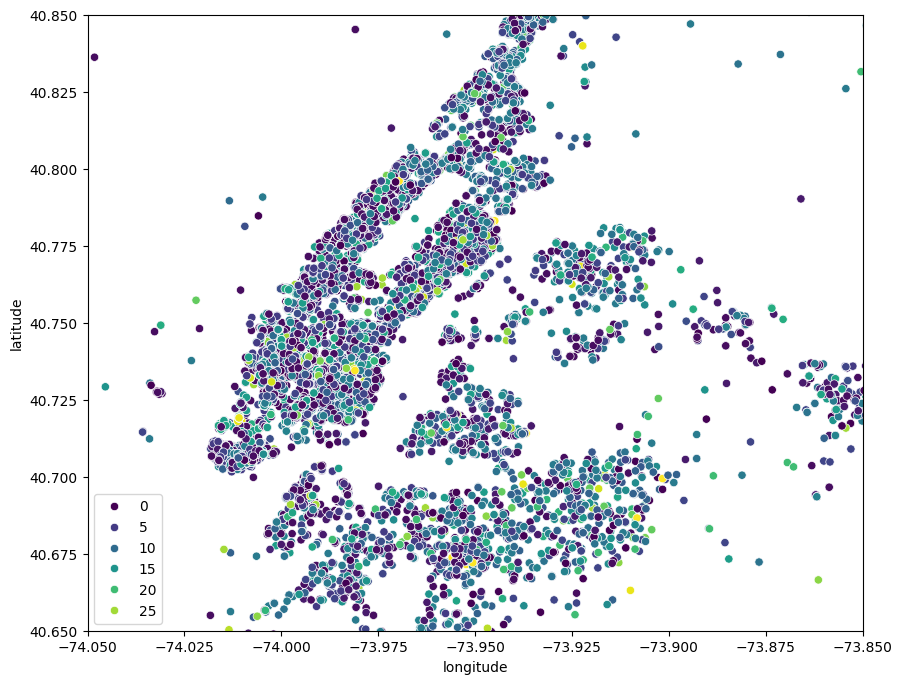

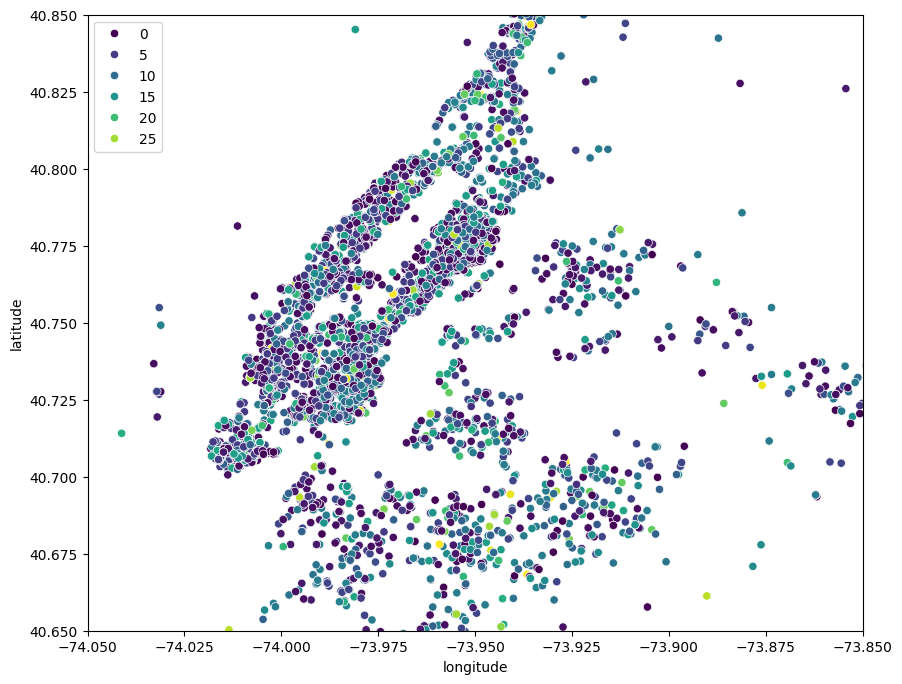

In [41]:
show_scatterplot(x=train['longitude'], y=train['latitude'], hue=train_pred_gm)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred_gm)

In [25]:
train_gm_X = train_X.copy()
train_gm_X['cluster'] = train_pred_gm
test_gm_X = test_X.copy()
test_gm_X['cluster'] = test_pred_gm

coef_gm = print_metrics(train_gm_X, test_gm_X, 'GaussianMixture Lasso')

Model: GaussianMixture Lasso
Train MAE: 685.7601429391954
Test MAE: 674.4111307449798
Train RMSE: 1000.0348258836456
Test RMSE: 967.2596517824192
Train R2: 0.609615503389993
Test R2: 0.605450516130504


In [26]:
features_cluster = features + ['cluster']
feature_importance_gm = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_gm)
})
feature_importance_gm = feature_importance_gm.sort_values('coef', ascending=True)
feature_importance_gm

,feature,coef
5,CatsAllowed,0.000000
18,Balcony,0.000000
15,OutdoorSpace,37.590214
12,Pre-War,48.324411
19,SwimmingPool,51.122690
21,NewConstruction,54.791843
6,DogsAllowed,58.455157
9,NoFee,86.249530
4,HardwoodFloors,99.289344
14,RoofDeck,102.275429


## 7. New features

In [27]:
features_cluster = features + ['cluster']
def sort_features(coef):
    df = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef)
})
    df = df.sort_values('coef', ascending=True)
    print(df)

In [28]:
df_metrics

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Base Lasso,690.696799,679.444960,1005.151020,972.074165,0.605611,0.601513
1,KMeans Lasso,686.317777,673.531715,1000.103576,966.228554,0.609562,0.606291
2,DBSCAN Lasso,680.735826,668.276556,993.824395,962.039946,0.614449,0.609697
3,AgglomerativeClustering Lasso,686.334864,701.004886,984.511368,1061.840102,0.609285,0.553050
4,GaussianMixture Lasso,685.760143,674.411131,1000.034826,967.259652,0.609616,0.605451


In [29]:
new_features = ['bathrooms',  'bedrooms', 'interest_level']

k_means = KMeans(n_clusters=30, n_init=10, random_state=0)
k_means.fit(train[new_features])

train_pred = k_means.predict(train[new_features])
test_pred = k_means.predict(test[new_features])

train_cluster_X = train_X.copy()
train_cluster_X['cluster'] = train_pred
test_cluster_X = test_X.copy()
test_cluster_X['cluster'] = test_pred

coef_new = print_metrics(train_cluster_X, test_cluster_X, 'KMeans Lasso 2')
sort_features(coef_new)

Model: KMeans Lasso 2
Train MAE: 686.8793035022787
Test MAE: 675.1799039372327
Train RMSE: 999.6315942360088
Test RMSE: 966.1112555617248
Train R2: 0.6099302597232312
Test R2: 0.6063868317523026
              feature          coef
5         CatsAllowed      0.000000
18            Balcony      0.000000
19       SwimmingPool     29.828515
15       OutdoorSpace     43.608001
21    NewConstruction     45.199261
12            Pre-War     45.909610
6         DogsAllowed     77.550685
9               NoFee     94.556936
4      HardwoodFloors     97.924689
14           RoofDeck    101.604885
22            Terrace    127.404874
8          Dishwasher    141.274772
16         DiningRoom    141.383714
20  LaundryInBuilding    161.127187
10  LaundryinBuilding    175.001933
3            Elevator    191.087359
11      FitnessCenter    208.915741
17  HighSpeedInternet    221.456895
13      LaundryinUnit    431.572907
7             Doorman    561.698838
23            cluster    696.947085
2      intere

In [30]:
dbscan = DBSCAN(eps=0.001, min_samples=5)
pred = dbscan.fit_predict(full_df[new_features])
train_pred_dbscan = pred[:train.shape[0]]
test_pred_dbscan = pred[train.shape[0]:]

train_dbscan_X = train_X.copy()
train_dbscan_X['cluster'] = train_pred_dbscan
test_dbscan_X = test_X.copy()
test_dbscan_X['cluster'] = test_pred_dbscan

coef_dbscan = print_metrics(train_dbscan_X, test_dbscan_X, 'DBSCAN Lasso 2')
sort_features(coef_dbscan)

Model: DBSCAN Lasso 2
Train MAE: 689.6788160169435
Test MAE: 678.3486969739881
Train RMSE: 1001.9337947387693
Test RMSE: 967.7447022930627
Train R2: 0.6081314913610923
Test R2: 0.605054708421739
              feature          coef
18            Balcony      0.000000
5         CatsAllowed      1.054282
19       SwimmingPool     29.616743
21    NewConstruction     42.701465
15       OutdoorSpace     43.508415
12            Pre-War     47.214902
6         DogsAllowed     74.585252
9               NoFee     95.366099
14           RoofDeck    100.880589
4      HardwoodFloors    106.346094
22            Terrace    123.974687
8          Dishwasher    135.974112
16         DiningRoom    141.300296
20  LaundryInBuilding    173.083110
10  LaundryinBuilding    179.971741
3            Elevator    195.495765
11      FitnessCenter    213.196616
17  HighSpeedInternet    219.571171
13      LaundryinUnit    436.044066
7             Doorman    566.270534
23            cluster    762.536097
2      intere

In [ ]:
sample = sample_cluster[new_features]
ac = AgglomerativeClustering(n_clusters=30)
ac.fit(sample)

labels = ac.labels_
sample_data['cluster'] = labels
ac_train_X, ac_test_X, ac_train_y, ac_test_y = train_test_split(
    sample_data, sample_target, test_size=0.2, random_state=42
)

train_x_mms = mms.fit_transform(ac_train_X)
test_x_mms = mms.transform(ac_test_X)

lasso.fit(train_x_mms, ac_train_y)

train_predict = lasso.predict(train_x_mms)
test_predict = lasso.predict(test_x_mms)

metrics_dict = {
    'Model': 'AgglomerativeClustering Lasso 2',
    'Train MAE': mean_absolute_error(ac_train_y, train_predict),
    'Test MAE': mean_absolute_error(ac_test_y, test_predict),
    'Train RMSE': mean_squared_error(ac_train_y, train_predict)**0.5,
    'Test RMSE': mean_squared_error(ac_test_y, test_predict)**0.5,
    'Train R2': r2_score(ac_train_y, train_predict),
    'Test R2': r2_score(ac_test_y, test_predict)
}

for k, v in metrics_dict.items():
    print(f"{k}: {v}")

df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

ac_coef = lasso.coef_
sort_features(ac_coef)

Model: AgglomerativeClustering Lasso 2
Train MAE: 686.3203463385308
Test MAE: 700.6092001870475
Train RMSE: 984.7177305300686
Test RMSE: 1062.4630586662263
Train R2: 0.6091207755683956
Test R2: 0.5525250173445975
              feature         coef
18            Balcony     4.286234
12            Pre-War    24.287038
5         CatsAllowed    27.662458
21    NewConstruction    33.483866
23            cluster    43.908339
19       SwimmingPool    55.796002
14           RoofDeck    56.591184
15       OutdoorSpace    63.467410
9               NoFee    77.817351
6         DogsAllowed    86.782285
16         DiningRoom    95.170652
8          Dishwasher   120.389530
4      HardwoodFloors   135.528007
11      FitnessCenter   159.255088
22            Terrace   186.432479
10  LaundryinBuilding   189.682501
17  HighSpeedInternet   196.803061
20  LaundryInBuilding   212.667572
3            Elevator   218.846046
13      LaundryinUnit   433.971959
7             Doorman   582.053634
2      interest_l

In [32]:
gm = GaussianMixture(n_components=30)
gm.fit(train[new_features])

train_pred_gm = gm.predict(train[new_features])
test_pred_gm = gm.predict(test[new_features])

train_gm_X = train_X.copy()
train_gm_X['cluster'] = train_pred_gm
test_gm_X = test_X.copy()
test_gm_X['cluster'] = test_pred_gm

coef_gm = print_metrics(train_gm_X, test_gm_X, 'GaussianMixture Lasso 2')
sort_features(coef_gm)

Model: GaussianMixture Lasso 2
Train MAE: 689.0948513136328
Test MAE: 676.871691372632
Train RMSE: 1001.8170464140146
Test RMSE: 967.0570893394225
Train R2: 0.608222809423593
Test R2: 0.6056157510572677
              feature          coef
5         CatsAllowed      0.000000
18            Balcony      0.000000
19       SwimmingPool     29.292067
15       OutdoorSpace     41.893023
12            Pre-War     48.603918
21    NewConstruction     51.944523
6         DogsAllowed     72.157695
9               NoFee     92.945275
4      HardwoodFloors    100.837971
14           RoofDeck    102.754455
22            Terrace    135.756858
8          Dishwasher    137.793670
16         DiningRoom    143.676785
20  LaundryInBuilding    166.837202
10  LaundryinBuilding    172.144250
3            Elevator    193.481222
11      FitnessCenter    206.399792
17  HighSpeedInternet    220.513774
13      LaundryinUnit    434.726924
23            cluster    452.673623
7             Doorman    558.199881
2    

## 8. Scoring

In [33]:
df_metrics

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Base Lasso,690.696799,679.444960,1005.151020,972.074165,0.605611,0.601513
1,KMeans Lasso,686.317777,673.531715,1000.103576,966.228554,0.609562,0.606291
2,DBSCAN Lasso,680.735826,668.276556,993.824395,962.039946,0.614449,0.609697
3,AgglomerativeClustering Lasso,686.334864,701.004886,984.511368,1061.840102,0.609285,0.553050
4,GaussianMixture Lasso,685.760143,674.411131,1000.034826,967.259652,0.609616,0.605451
5,KMeans Lasso 2,686.879304,675.179904,999.631594,966.111256,0.609930,0.606387
6,DBSCAN Lasso 2,689.678816,678.348697,1001.933795,967.744702,0.608131,0.605055
7,AgglomerativeClustering Lasso 2,686.320346,700.609200,984.717731,1062.463059,0.609121,0.552525
8,GaussianMixture Lasso 2,689.094851,676.871691,1001.817046,967.057089,0.608223,0.605616
